# Analysis-period DA scorecard: plot

Heat maps from the tables written by `04_compute_da_scorecard_metrics.ipynb` (no model data are read here).

* **Figure 1:** S0, % change in error of DART10/20/40 relative to CTRL10 (no DA). Rows in groups A/B score the analysis; groups C/D score daily means of the 6-h forecasts.
* **Figure 2:** DART40-S0 vs DART40-S1, RMSE normalised by the reference variability of each window (std about the grid-point window mean), so the two seasons can be compared. No CTRL ran during the S1 window, so a Figure-1-style change vs CTRL is not possible for S1.

Rows: experiments within each latitude band; columns: variables. PSL is left out (see `exclude_variables`).

Figure 1: blue = error reduced, red = increased (numbers are exact). Hatched cells: the 95% block-bootstrap interval includes 0. Figure 2: values below 1 mean the error is smaller than the natural variability of that window. Figures are written as PDF.

**Verification window (both seasons, every row, every experiment): 64 assimilation cycles.**

| | S0 | S1 |
|---|---|---|
| Analyses | 16 Dec 2011 00Z – 31 Dec 18Z | 16 May 2012 00Z – 31 May 18Z |
| 6-h forecasts (prior) valid | 16 Dec 00Z – 1 Jan 00Z | 16 May 00Z – 1 Jun 00Z |
| Daily rows | 16–31 Dec | 16–31 May |

These are the same cycles as the state-space notebooks (06/07) and the common-observation `obs_diag` products (whose 1 Jan / 1 Jun 00Z bin holds no common observations). The all-observation products in notebooks 03/04 also include the 1 Jan 00Z cycle.

## 1. Settings

In [1]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
workflow_name = "analysis_atm_model_evaluation"
workflow_subdir = "da_scorecard"
# Pressure-level DART summaries (prior/posterior mean and sd), 1 degree.
REMAP_ROOT = DIAGNOSTIC_OUTPUT_ROOT / "data/analysis_atm_init/remapped_ensemble_diagnostics"

# PSL omitted: its tropical errors are dominated by artefacts, not the DA signal.
exclude_variables = ["PSL"]
region_order = ["Global", "Tropics", "NH extratropics", "SH extratropics"]  # top to bottom
score = "rmse"         # Figure 1: "rmse" or "crps" (Figure 2 is RMSE only)
fig1_color_limit = 80  # percent; DART vs CTRL changes are large
fig2_levels = [round(0.1 * k, 1) for k in range(15)]  # normalised RMSE, 0-1.4
FIGURE_DPI = 200
fontsize = 18          # base (tick-label) font size; layout scales with it
show = True

## 2. Project setup

In [2]:
import sys
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
import pandas as pd
import matplotlib.pyplot as plt
from util.da_scorecard import default_rows, plot_change_heatmap

data_dir, figure_dir = workflow_output_dirs(workflow_name, workflow_subdir, output_root=DIAGNOSTIC_OUTPUT_ROOT)

variable_order = [r.name for r in default_rows() if r.name not in exclude_variables]
fig1 = pd.read_csv(data_dir / f"fig1_dart_vs_ctrl_{score}_change.csv")
fig2 = pd.read_csv(data_dir / "fig2_normalized_rmse.csv")
score_label = {"rmse": "RMSE", "crps": "CRPS"}[score]

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 3. Figure 1: S0 with vs without DA

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/analysis_atm_model_evaluation/da_scorecard/fig1_scorecard_dart_vs_ctrl_S0_rmse.pdf


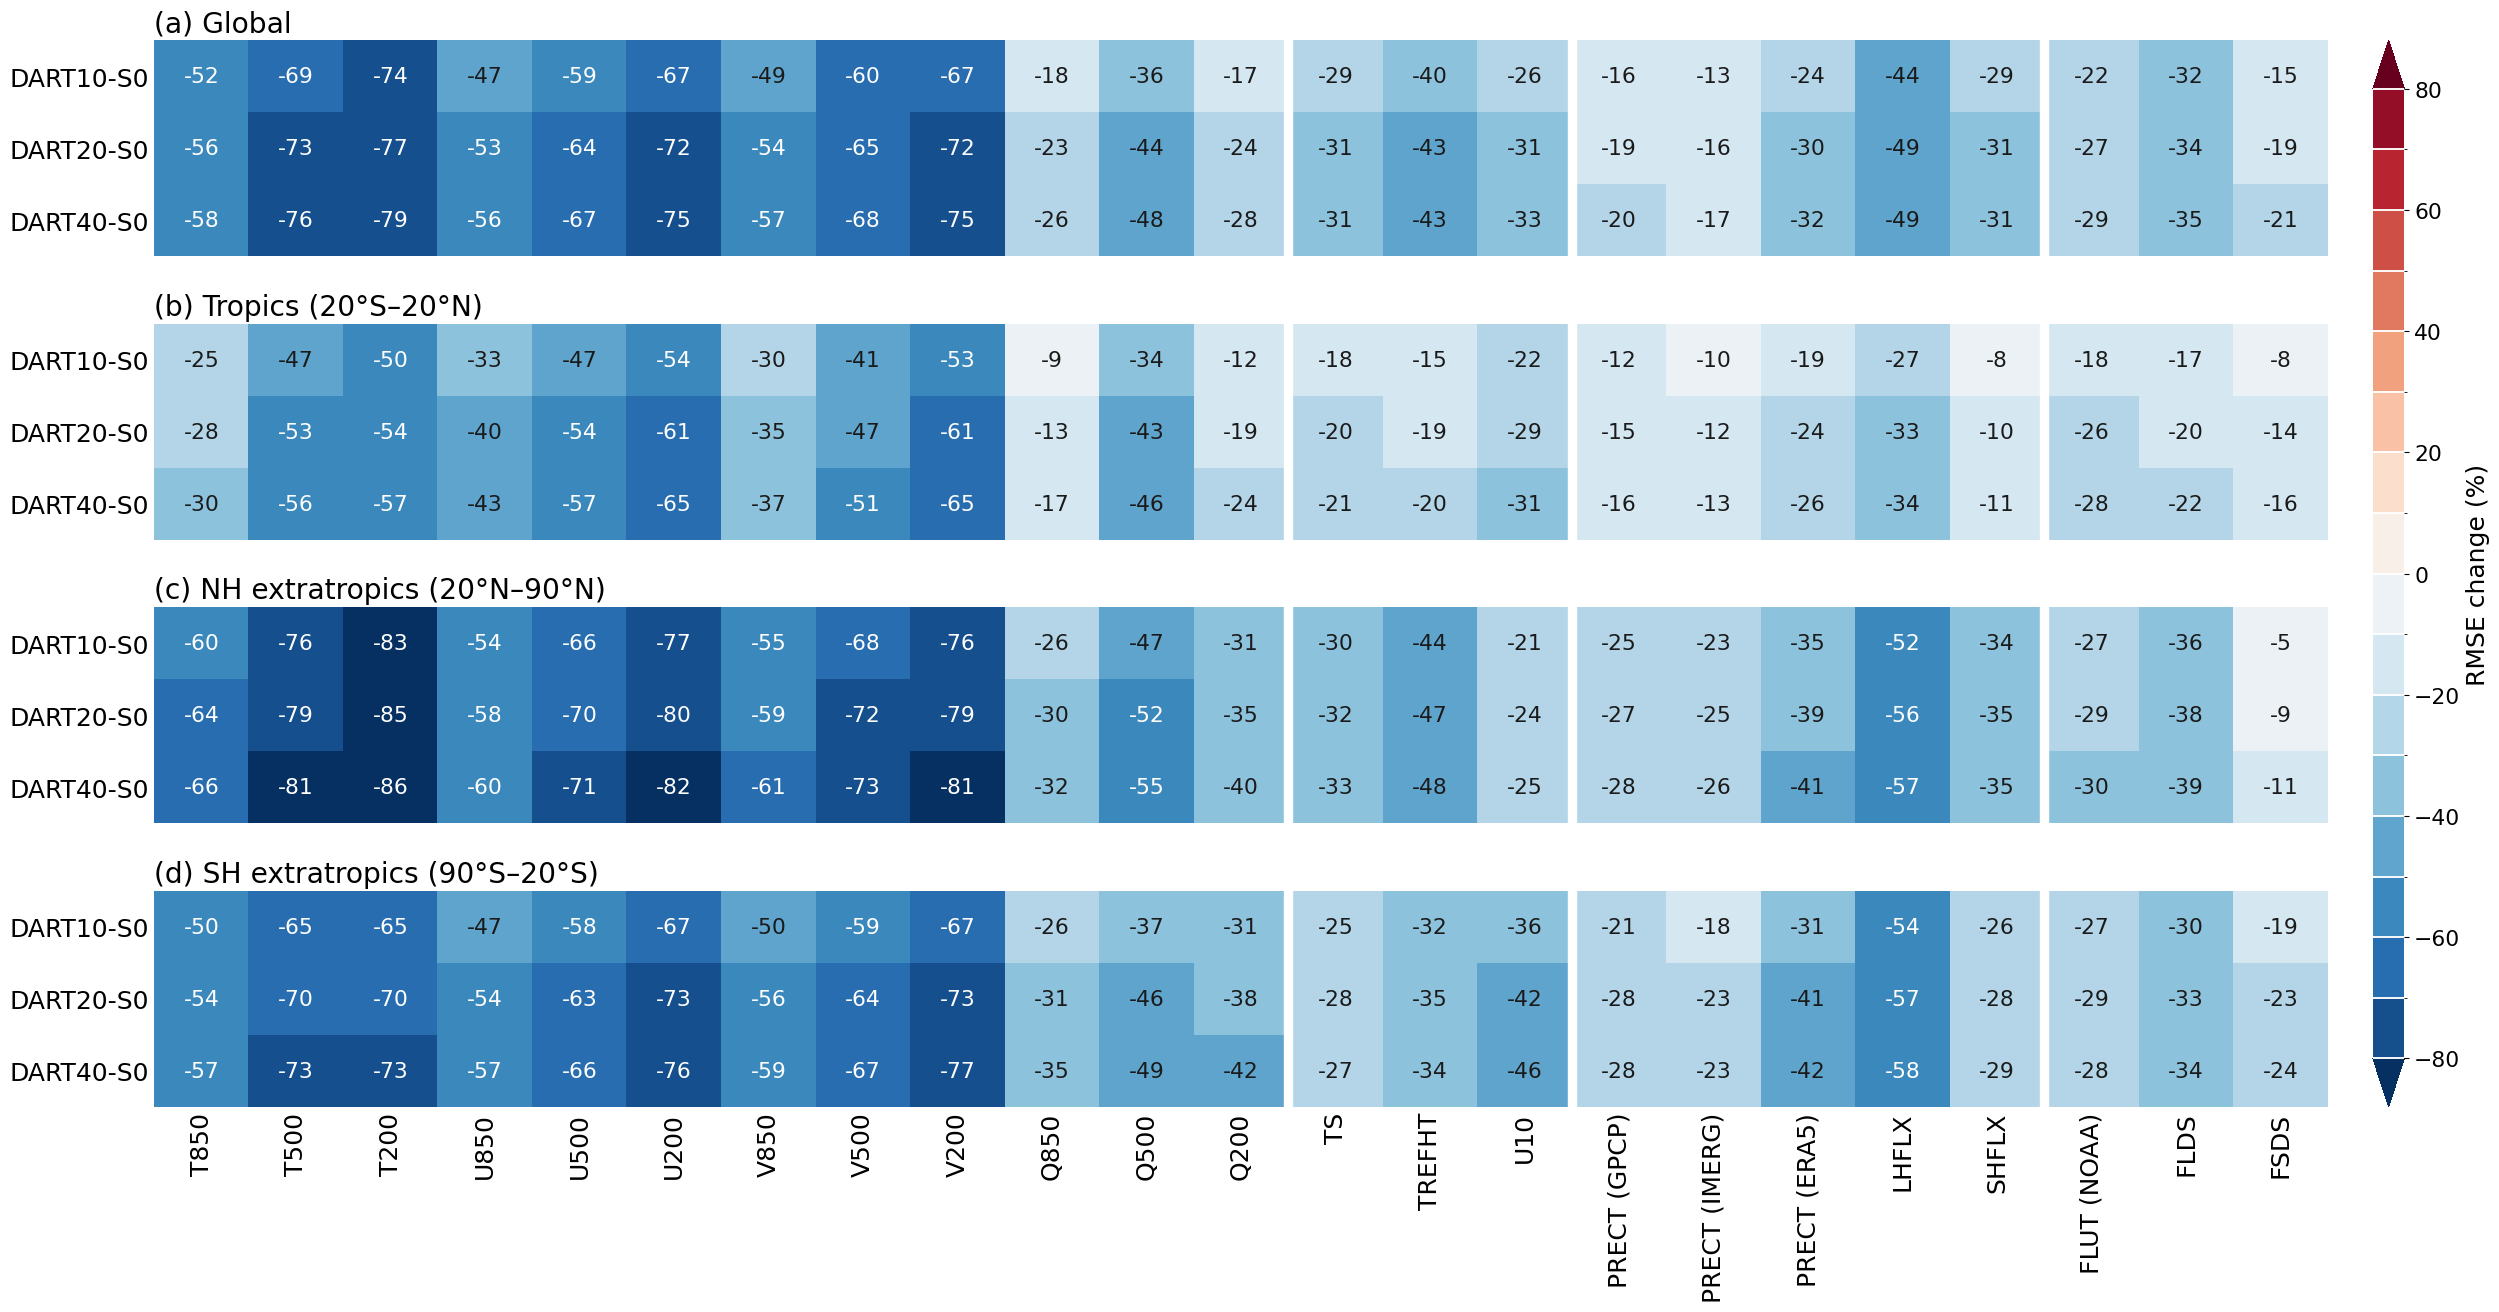

In [3]:
fig = plot_change_heatmap(
    fig1, variable_order=variable_order, region_order=region_order, experiment_order=["DART10-S0", "DART20-S0", "DART40-S0"],
    experiment_label=lambda r: r.test, limit=fig1_color_limit,
    fontsize=fontsize,
    cbar_label=f"{score_label} change (%)",
)
output = figure_dir / f"fig1_scorecard_dart_vs_ctrl_S0_{score}.pdf"
fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")  # dpi only affects hatching
print(f"[FIGURE] {output}")
if not show:
    plt.close(fig)

## 4. Figure 2: DART40 normalised RMSE, S0 vs S1

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/analysis_atm_model_evaluation/da_scorecard/fig2_scorecard_normalized_rmse_DART40_S0_S1.pdf


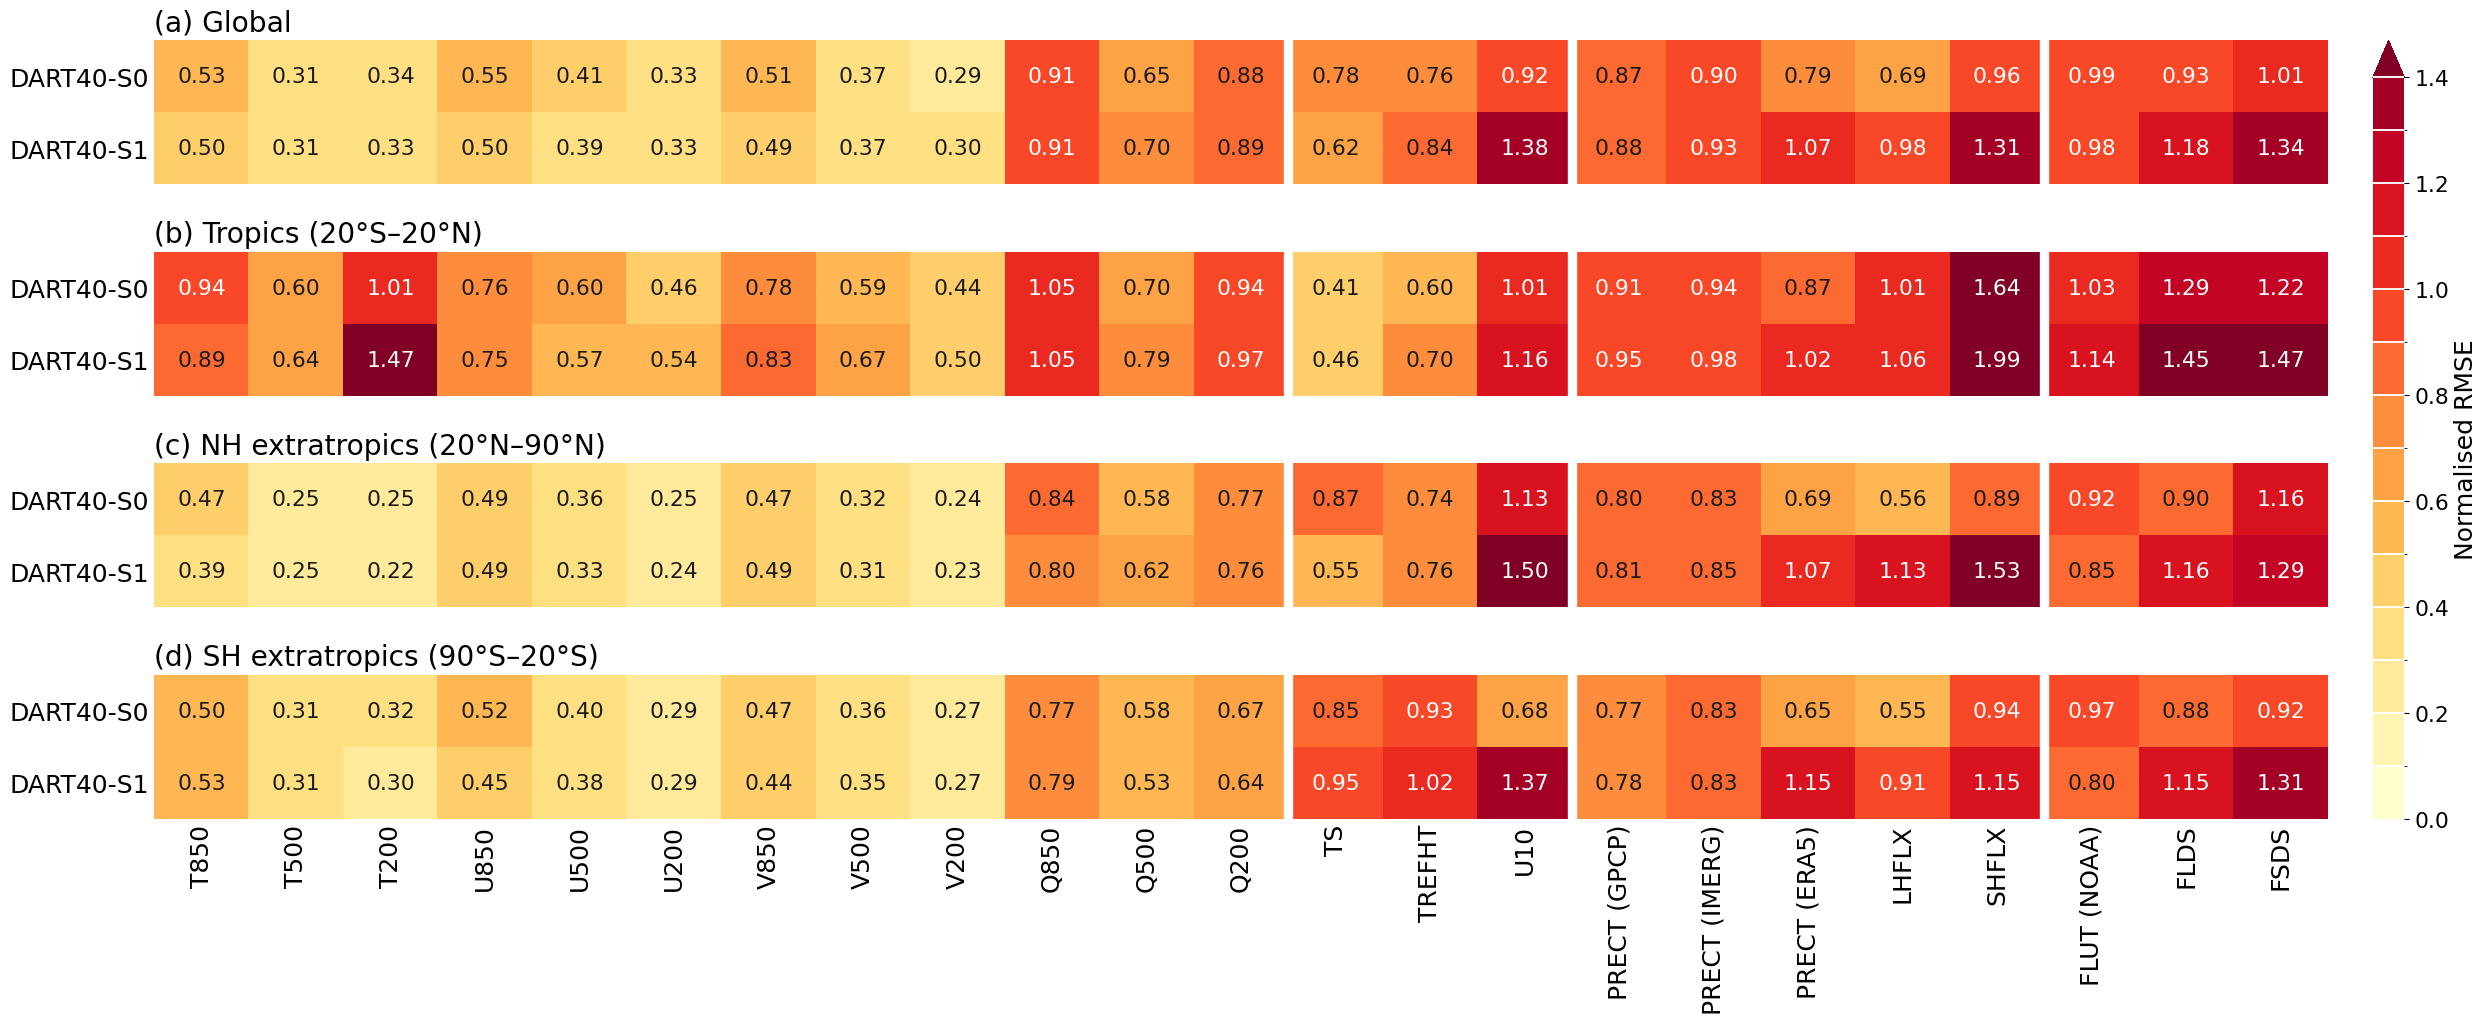

In [4]:
fig = plot_change_heatmap(
    fig2, variable_order=variable_order, region_order=region_order, experiment_order=["DART40-S0", "DART40-S1"],
    experiment_label=lambda r: r.test, value="nrmse", levels=fig2_levels, cmap="YlOrRd", fmt="{:.2f}",
    fontsize=fontsize,
    cbar_label="Normalised RMSE",
)
output = figure_dir / "fig2_scorecard_normalized_rmse_DART40_S0_S1.pdf"
fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
print(f"[FIGURE] {output}")
if not show:
    plt.close(fig)